# PRCP-1018 | Bike Rental Demand Prediction
### Complete capstone project · Exploratory analysis, forecasting, model comparison & challenges
**Source:** Capital Bikeshare, Washington DC, 2011–2012; dataset by Hadi Fanaee-T and João Gama.  
**Goal:** Predict **daily total rentals (`cnt`)** using calendar and environmental variables.  
**Deliverable:** All tasks in **one** Google Colab-compatible Jupyter notebook.

> **How to run in Google Colab:** Upload this notebook to Colab, then run cells in order (**Runtime → Run all**). When prompted, upload **both `day.csv` and `hour.csv`**. The same notebook also runs locally if those files are beside it.

**Source notes:** `Readme.txt` supplies the dataset's season mapping (1=spring, 2=summer, 3=fall, 4=winter); this differs from the wording in the capstone brief. We follow the original dataset Readme. No values from `casual` or `registered` are used to predict `cnt`, because they sum to the answer.

## 0 · Executive overview
This notebook executes all four required deliverables: (1) full data analysis, (2) daily rental prediction, (3) comparison of multiple models and production recommendation, and (4) challenges and justified solutions. **Results and recommendations are generated from the executed data, not hardcoded.**

**Important scope:** Historical 2011–2012 observations are not evidence of today's demand. The evaluation tests generalization to later dates within the dataset, not to the present day.

## 1 · Environment and reproducibility

#### Code cell 1 — Import required libraries

**What this code does:** Pandas reads and cleans tables; NumPy handles numbers; Matplotlib and Seaborn draw graphs; scikit-learn trains and evaluates regression models.

In [1]:
# Import required libraries.
# Pandas reads and cleans tables; NumPy handles numbers; Matplotlib and Seaborn draw graphs; scikit-learn trains and evaluates regression models.
# Standard Colab packages; no pip install required on a normal Colab runtime.
import os, warnings, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import sklearn
SEED=42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='deep', context='notebook')
plt.rcParams.update({'figure.figsize':(10,5),'axes.titlesize':13,'axes.labelsize':11,'figure.dpi':110})
pd.set_option('display.max_columns',25)
print('Python:',sys.version.split()[0], '| pandas:',pd.__version__,'| scikit-learn:',sklearn.__version__)

Python: 3.13.18 | pandas: 2.2.3 | scikit-learn: 1.6.1


### 1.1 · Locate or upload source CSV files

#### Code cell 2 — Upload and read the CSV files

**What this code does:** Find day.csv and hour.csv. In Colab, a file-upload dialog appears if they are missing. Read dates as dates, not text.

In [2]:
# Upload and read the CSV files.
# Find day.csv and hour.csv. In Colab, a file-upload dialog appears if they are missing. Read dates as dates, not text.
# Colab: upload both CSV files once when prompted. Local: keep both beside the notebook.
def find_csv(filename):
    for directory in [Path.cwd(), Path('/content'), Path('/mnt/data')]:
        candidate = directory / filename
        if candidate.is_file(): return candidate
    return None

if find_csv('day.csv') is None or find_csv('hour.csv') is None:
    try:
        from google.colab import files
        print('Please upload day.csv and hour.csv together:')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Place day.csv and hour.csv in the notebook working directory.')

day_path, hour_path = find_csv('day.csv'), find_csv('hour.csv')
assert day_path is not None and hour_path is not None, 'Both CSV files are required.'
day = pd.read_csv(day_path, parse_dates=['dteday'])
hour = pd.read_csv(hour_path, parse_dates=['dteday'])
print('Loaded:',day_path,day.shape,'and',hour_path,hour.shape)

Loaded: /content/day.csv (731, 16) and /content/hour.csv (17379, 17)


## 2 · Task 1: Data understanding and quality checks

#### Code cell 3 — Display the first records

**What this code does:** head(5) shows five sample rows. The date-range print checks which period is covered.

In [3]:
# Display the first records.
# head(5) shows five sample rows. The date-range print checks which period is covered.
display(day.head(5))
display(hour.head(5))
print('Daily date range:',day.dteday.min().date(),'to',day.dteday.max().date())
print('Hourly date range:',hour.dteday.min().date(),'to',hour.dteday.max().date())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Daily date range: 2011-01-01 to 2012-12-31
Hourly date range: 2011-01-01 to 2012-12-31


#### Code cell 4 — Check data quality

**What this code does:** Count rows, columns, missing values, and duplicates. The assert statements stop execution if important data rules fail.

In [4]:
# Check data quality.
# Count rows, columns, missing values, and duplicates. The assert statements stop execution if important data rules fail.
quality = pd.DataFrame({
 'Dataset':['day.csv','hour.csv'],
 'Rows':[len(day),len(hour)],
 'Columns':[day.shape[1],hour.shape[1]],
 'Missing cells':[int(day.isna().sum().sum()),int(hour.isna().sum().sum())],
 'Duplicate rows':[int(day.duplicated().sum()),int(hour.duplicated().sum())],
 'Duplicate dates':[int(day.dteday.duplicated().sum()),int(hour.dteday.duplicated().sum())]
})
display(quality)
print('Note: repeated dates are EXPECTED in hourly data (different hours of the same day).')
assert day['cnt'].eq(day['casual']+day['registered']).all()
assert hour['cnt'].eq(hour['casual']+hour['registered']).all()
assert not day['dteday'].duplicated().any()
assert day['cnt'].ge(0).all() and hour['cnt'].ge(0).all()
print('PASS: target identity, unique daily dates, and nonnegative counts.')

,Dataset,Rows,Columns,Missing cells,Duplicate rows,Duplicate dates
0,day.csv,731,16,0,0,0
1,hour.csv,17379,17,0,0,16648


Note: repeated dates are EXPECTED in hourly data (different hours of the same day).
PASS: target identity, unique daily dates, and nonnegative counts.


### 2.1 · Cross-check daily totals against the hourly records

#### Code cell 5 — Verify daily and hourly totals

**What this code does:** groupby adds hourly rentals for each date; merge matches the result with the daily file. Differences should be zero.

In [5]:
# Verify daily and hourly totals.
# groupby adds hourly rentals for each date; merge matches the result with the daily file. Differences should be zero.
daily_hourly = hour.groupby('dteday',as_index=False)['cnt'].sum().rename(columns={'cnt':'hourly_sum'})
reconcile = day[['dteday','cnt']].merge(daily_hourly,on='dteday',how='left',validate='one_to_one')
reconcile['difference']=reconcile['cnt']-reconcile['hourly_sum']
print('Dates with differing totals:',int(reconcile['difference'].ne(0).sum()))
print('Maximum absolute difference:',reconcile['difference'].abs().max())
display(reconcile.head())

Dates with differing totals: 0
Maximum absolute difference: 0


,dteday,cnt,hourly_sum,difference
0,2011-01-01,985,985,0
1,2011-01-02,801,801,0
2,2011-01-03,1349,1349,0
3,2011-01-04,1562,1562,0
4,2011-01-05,1600,1600,0


### 2.2 · Descriptive statistics and target distribution

#### Code cell 6 — Summary statistics and distribution

**What this code does:** describe() reports count, mean, standard deviation, and quartiles. A histogram shows frequency; a box plot shows spread.

,cnt,casual,registered,temp,atemp,hum,windspeed
count,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,4504.35,848.18,3656.17,0.50,0.47,0.63,0.19
std,1937.21,686.62,1560.26,0.18,0.16,0.14,0.08
min,22.00,2.00,20.00,0.06,0.08,0.00,0.02
25%,3152.00,315.50,2497.00,0.34,0.34,0.52,0.13
50%,4548.00,713.00,3662.00,0.50,0.49,0.63,0.18
75%,5956.00,1096.00,4776.50,0.66,0.61,0.73,0.23
max,8714.00,3410.00,6946.00,0.86,0.84,0.97,0.51


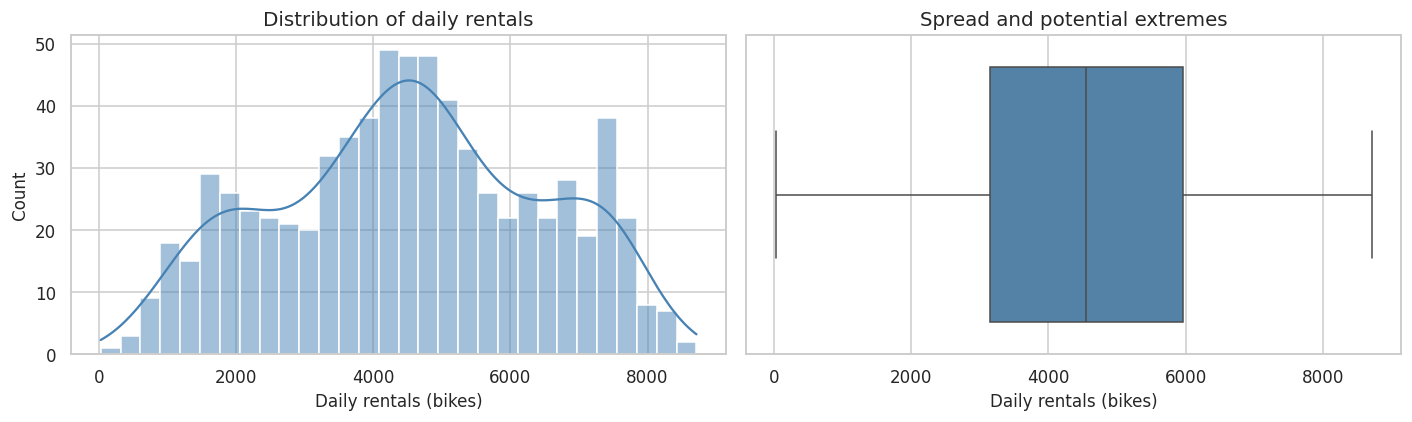

In [6]:
# Summary statistics and distribution.
# describe() reports count, mean, standard deviation, and quartiles. A histogram shows frequency; a box plot shows spread.
display(day[['cnt','casual','registered','temp','atemp','hum','windspeed']].describe().round(2))
fig,axs=plt.subplots(1,2,figsize=(13,4))
sns.histplot(data=day,x='cnt',bins=30,kde=True,color='steelblue',ax=axs[0]);axs[0].set(title='Distribution of daily rentals',xlabel='Daily rentals (bikes)')
sns.boxplot(data=day,x='cnt',color='steelblue',ax=axs[1]);axs[1].set(title='Spread and potential extremes',xlabel='Daily rentals (bikes)')
plt.tight_layout()
plt.show()

### 2.3 · Daily trend and rolling average

#### Code cell 7 — Plot rental demand over time

**What this code does:** Sort the dates and draw daily rental counts. A rolling average smooths day-to-day fluctuations.

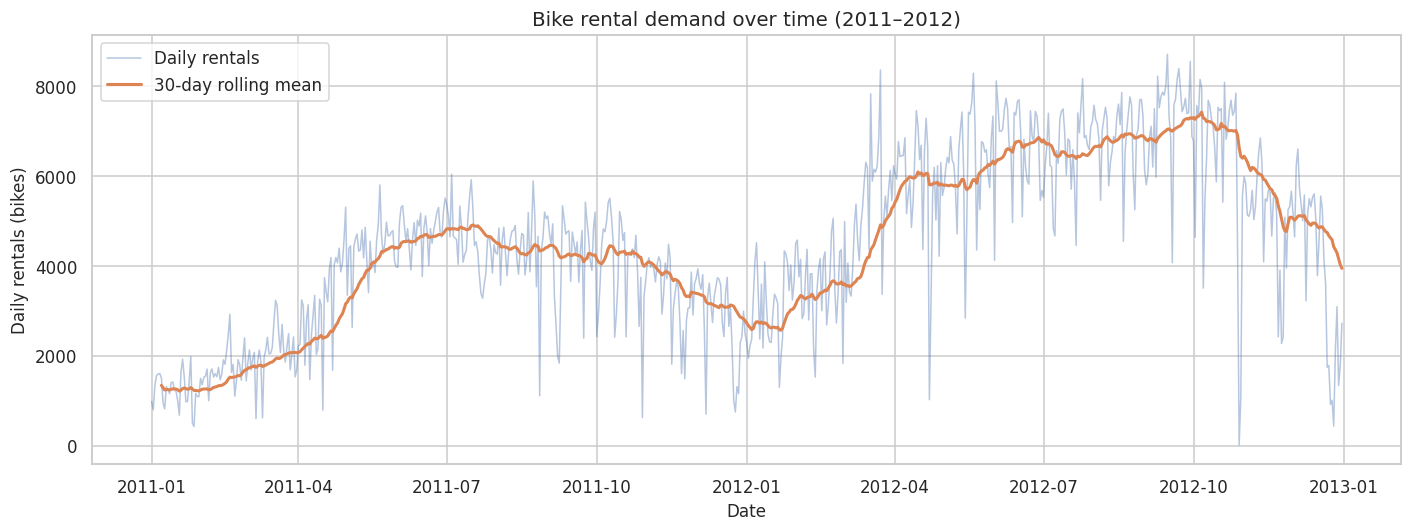

In [7]:
# Plot rental demand over time.
# Sort the dates and draw daily rental counts. A rolling average smooths day-to-day fluctuations.
day=day.sort_values('dteday').reset_index(drop=True)
fig,ax=plt.subplots(figsize=(13,5))
ax.plot(day.dteday,day.cnt,alpha=.40,label='Daily rentals',linewidth=1)
ax.plot(day.dteday,day.cnt.rolling(30,min_periods=7).mean(),linewidth=2,label='30-day rolling mean')
ax.set(title='Bike rental demand over time (2011–2012)',xlabel='Date',ylabel='Daily rentals (bikes)');ax.legend()
plt.tight_layout()
plt.show()

### 2.4 · Demand by season and weather

#### Code cell 8 — Compare seasons and weather

**What this code does:** Convert numeric season/weather codes to readable labels. Group by each category and compare average rental demand.

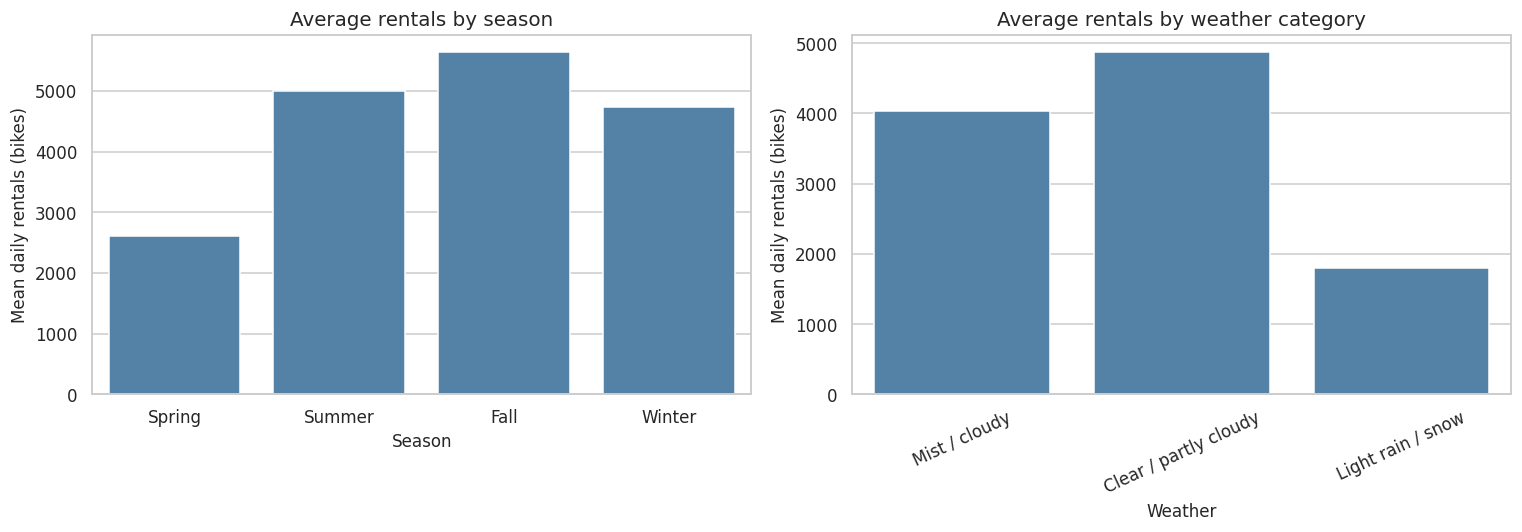

,count,mean,median
Season,,,
Fall,188,5644.3,5353.5
Spring,181,2604.1,2209.0
Summer,184,4992.3,4941.5
Winter,178,4728.2,4634.5


,count,mean,median
Weather,,,
Clear / partly cloudy,463,4876.8,4844.0
Light rain / snow,21,1803.3,1817.0
Mist / cloudy,247,4035.9,4040.0


In [8]:
# Compare seasons and weather.
# Convert numeric season/weather codes to readable labels. Group by each category and compare average rental demand.
season_map={1:'Spring',2:'Summer',3:'Fall',4:'Winter'}
weather_map={1:'Clear / partly cloudy',2:'Mist / cloudy',3:'Light rain / snow',4:'Heavy rain / snow'}
eda=day.copy();eda['Season']=eda.season.map(season_map);eda['Weather']=eda.weathersit.map(weather_map)
fig,axs=plt.subplots(1,2,figsize=(14,5))
sns.barplot(data=eda,x='Season',y='cnt',order=['Spring','Summer','Fall','Winter'],errorbar=None,color='steelblue',ax=axs[0]);axs[0].set(title='Average rentals by season',ylabel='Mean daily rentals (bikes)',xlabel='Season')
sns.barplot(data=eda,x='Weather',y='cnt',errorbar=None,color='steelblue',ax=axs[1]);axs[1].tick_params(axis='x',rotation=25);axs[1].set(title='Average rentals by weather category',ylabel='Mean daily rentals (bikes)',xlabel='Weather')
plt.tight_layout()
plt.show()
display(eda.groupby('Season')['cnt'].agg(['count','mean','median']).round(1))
display(eda.groupby('Weather')['cnt'].agg(['count','mean','median']).round(1))

### 2.5 · Working days, months and years

#### Code cell 9 — Compare months and weekdays

**What this code does:** Bar charts help show which months and weekdays have higher average rental demand.

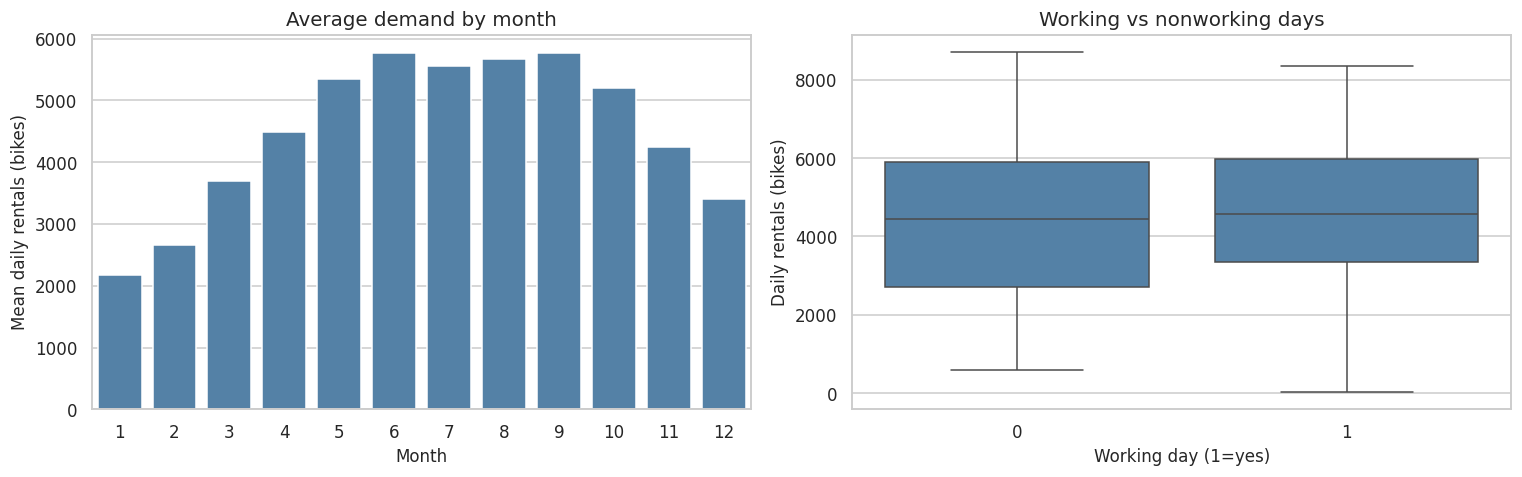

,count,mean,median
yr,,,
2011,365,3405.8,3740.0
2012,366,5599.9,5927.0


In [9]:
# Compare months and weekdays.
# Bar charts help show which months and weekdays have higher average rental demand.
fig,axs=plt.subplots(1,2,figsize=(14,4.5))
sns.barplot(data=day,x='mnth',y='cnt',errorbar=None,color='steelblue',ax=axs[0]);axs[0].set(title='Average demand by month',xlabel='Month',ylabel='Mean daily rentals (bikes)')
sns.boxplot(data=day,x='workingday',y='cnt',color='steelblue',ax=axs[1]);axs[1].set(title='Working vs nonworking days',xlabel='Working day (1=yes)',ylabel='Daily rentals (bikes)')
plt.tight_layout()
plt.show()
display(day.groupby('yr')['cnt'].agg(['count','mean','median']).rename(index={0:'2011',1:'2012'}).round(1))

### 2.6 · Hourly patterns (supplementary EDA only)

#### Code cell 10 — Explore hourly demand

**What this code does:** Use hour.csv only for extra EDA. Compare hourly rental patterns on working and nonworking days.

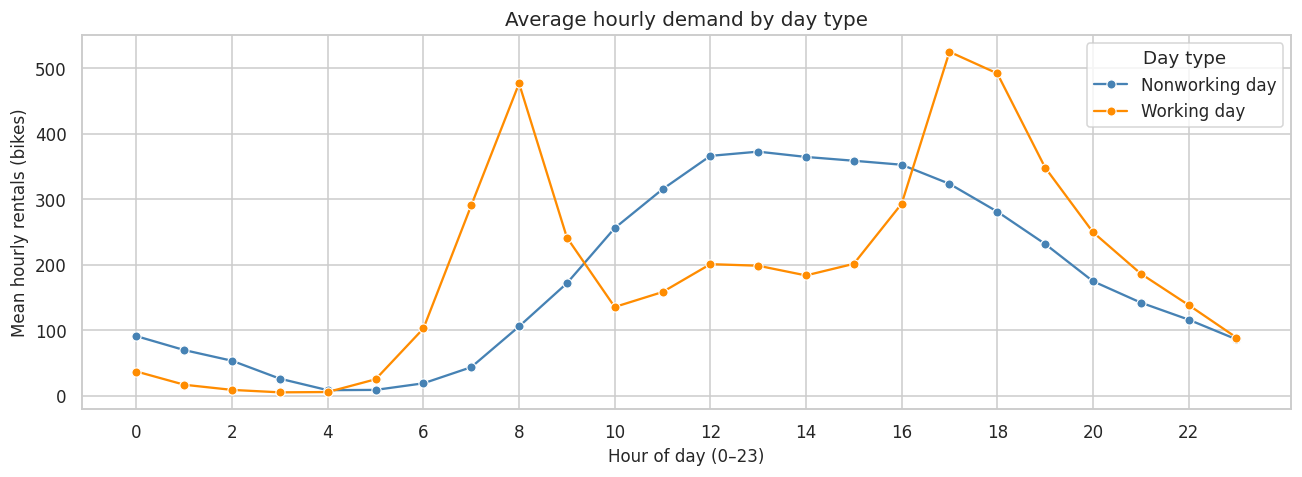

The hourly data is analyzed for context; the model target remains DAILY count.


In [10]:
# Explore hourly demand.
# Use hour.csv only for extra EDA. Compare hourly rental patterns on working and nonworking days.
hour_plot=hour.copy();hour_plot['Day type']=np.where(hour_plot.workingday.eq(1),'Working day','Nonworking day')
by_hour=hour_plot.groupby(['hr','Day type'],as_index=False)['cnt'].mean()
fig,ax=plt.subplots(figsize=(12,4.5))
sns.lineplot(data=by_hour,x='hr',y='cnt',hue='Day type',marker='o',palette=['steelblue','darkorange'],ax=ax)
ax.set(title='Average hourly demand by day type',xlabel='Hour of day (0–23)',ylabel='Mean hourly rentals (bikes)');ax.set_xticks(range(0,24,2))
plt.tight_layout()
plt.show()
print('The hourly data is analyzed for context; the model target remains DAILY count.')

### 2.7 · Correlation analysis (descriptive, not causal)

#### Code cell 11 — Correlation heatmap

**What this code does:** corr() measures linear relationships between numerical columns. Correlation alone does not prove causation.

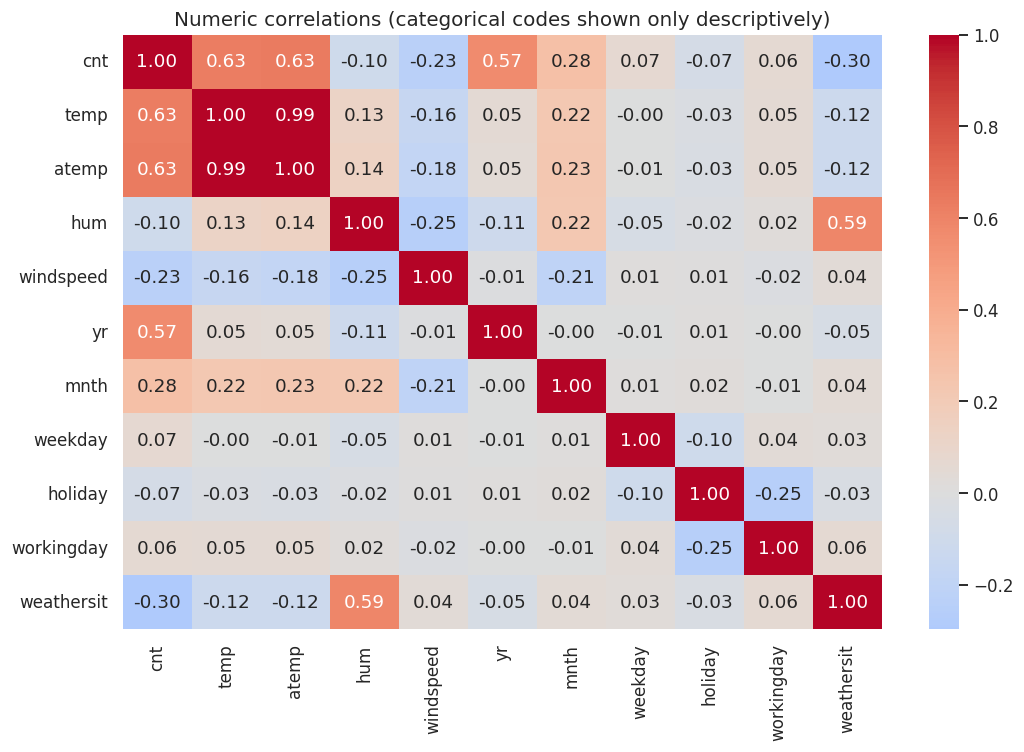

Caution: correlations of numeric category codes do not imply a linear ordinal relationship.


In [11]:
# Correlation heatmap.
# corr() measures linear relationships between numerical columns. Correlation alone does not prove causation.
corr_cols=['cnt','temp','atemp','hum','windspeed','yr','mnth','weekday','holiday','workingday','weathersit']
fig,ax=plt.subplots(figsize=(10,7))
sns.heatmap(day[corr_cols].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0,ax=ax)
ax.set_title('Numeric correlations (categorical codes shown only descriptively)')
plt.tight_layout()
plt.show()
print('Caution: correlations of numeric category codes do not imply a linear ordinal relationship.')

### EDA interpretation (automatically computed)
The summaries below describe associations, **not** causal effects. Sparse weather categories must be interpreted cautiously.

#### Code cell 12 — Summarize EDA findings

**What this code does:** Calculate real averages from the data so the report contains measured observations, not guesses.

In [12]:
# Summarize EDA findings.
# Calculate real averages from the data so the report contains measured observations, not guesses.
season_stats=eda.groupby('Season')['cnt'].mean().sort_values(ascending=False)
weather_stats=eda.groupby('Weather')['cnt'].agg(['mean','count']).sort_values('mean',ascending=False)
print(f'Highest observed mean demand season: {season_stats.index[0]} ({season_stats.iloc[0]:,.0f} rentals/day).')
print(f'Lowest observed mean demand season: {season_stats.index[-1]} ({season_stats.iloc[-1]:,.0f} rentals/day).')
print(f'Observed mean daily demand: {day.cnt.mean():,.0f}; median: {day.cnt.median():,.0f}.')
print('Weather category sample sizes (important for interpreting means):')
display(weather_stats.round(1))

Highest observed mean demand season: Fall (5,644 rentals/day).
Lowest observed mean demand season: Spring (2,604 rentals/day).
Observed mean daily demand: 4,504; median: 4,548.
Weather category sample sizes (important for interpreting means):


,mean,count
Weather,,
Clear / partly cloudy,4876.8,463
Mist / cloudy,4035.9,247
Light rain / snow,1803.3,21


## 3 · Task 2: Predict daily bike rental demand

### Modeling decisions and leakage controls
- **Target:** `cnt` (daily rentals).
- **Exclude:** `casual` and `registered` (their sum equals the target); `instant` (row identifier); `dteday` (raw timestamp; its calendar components are available).
- **Inputs:** calendar flags and weather measurements. `yr` is retained to represent the historical growth trend, but predicting years outside 2011–2012 requires caution.
- **Split:** earliest 80% of days for development, latest 20% held out for final testing. This is a chronological test, not a random split.
- **Validation:** expanding-window `TimeSeriesSplit` on training data only.
- **Preprocessing:** category one-hot encoding; imputation and scaling fitted only on training folds via pipelines.
- **No observed rental counts or lagged target values** are used as predictors. Weather inputs for future dates must come from forecasts, not future observations.

#### Code cell 13 — Select inputs and split by date

**What this code does:** X contains the input features; y is the total rentals. Remove casual and registered because they reveal the answer. Use earlier dates to train and later dates to test.

In [13]:
# Select inputs and split by date.
# X contains the input features; y is the total rentals. Remove casual and registered because they reveal the answer. Use earlier dates to train and later dates to test.
categorical=['season','mnth','weekday','holiday','workingday','weathersit']
numeric=['yr','temp','atemp','hum','windspeed']
features=categorical+numeric
X=day[features].copy(); y=day['cnt'].astype(float).copy()
cut=int(len(day)*.80)
X_train,X_test=X.iloc[:cut].copy(),X.iloc[cut:].copy()
y_train,y_test=y.iloc[:cut].copy(),y.iloc[cut:].copy()
train_dates=day.dteday.iloc[:cut];test_dates=day.dteday.iloc[cut:]
assert train_dates.max()<test_dates.min()
print(f'Train: {len(X_train)} days, {train_dates.min().date()} to {train_dates.max().date()}')
print(f'Test:  {len(X_test)} days, {test_dates.min().date()} to {test_dates.max().date()}')
print('Features:',features)

Train: 584 days, 2011-01-01 to 2012-08-06
Test:  147 days, 2012-08-07 to 2012-12-31
Features: ['season', 'mnth', 'weekday', 'holiday', 'workingday', 'weathersit', 'yr', 'temp', 'atemp', 'hum', 'windspeed']


### 3.1 · Define preprocessing and regression candidates

#### Code cell 14 — Prepare three regression models

**What this code does:** OneHotEncoder handles category codes, StandardScaler scales numerical values, and Pipeline applies preparation correctly during validation.

In [14]:
# Prepare three regression models.
# OneHotEncoder handles category codes, StandardScaler scales numerical values, and Pipeline applies preparation correctly during validation.
def make_encoder():
    # Compatibility across older/newer scikit-learn releases.
    try: return OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError: return OneHotEncoder(handle_unknown='ignore',sparse=False)

preprocess=ColumnTransformer([
 ('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',make_encoder())]),categorical),
 ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric)
],remainder='drop')
models={
 'Ridge Regression':Ridge(alpha=10.0),
 'Random Forest':RandomForestRegressor(n_estimators=180,min_samples_leaf=3,max_features=0.9,random_state=SEED,n_jobs=-1),
 'Histogram Gradient Boosting':HistGradientBoostingRegressor(max_iter=160,learning_rate=.06,max_leaf_nodes=15,l2_regularization=5,random_state=SEED)
}
pipelines={name:Pipeline([('preprocess',preprocess),('model',estimator)]) for name,estimator in models.items()}
print('Models:',', '.join(pipelines))

Models: Ridge Regression, Random Forest, Histogram Gradient Boosting


### 3.2 · Time-series cross-validation on training period

#### Code cell 15 — Compare models using time-series cross-validation

**What this code does:** TimeSeriesSplit keeps training observations earlier than validation observations. Compare average MAE and RMSE without looking at the final test set.

In [15]:
# Compare models using time-series cross-validation.
# TimeSeriesSplit keeps training observations earlier than validation observations. Compare average MAE and RMSE without looking at the final test set.
cv=TimeSeriesSplit(n_splits=4)
cv_rows=[]
for name,pipe in pipelines.items():
    scores=cross_validate(pipe,X_train,y_train,cv=cv,scoring={'mae':'neg_mean_absolute_error','r2':'r2'},n_jobs=1,error_score='raise')
    cv_rows.append({'Model':name,'CV MAE (bikes)':-scores['test_mae'].mean(),'CV MAE SD':scores['test_mae'].std(),'CV R²':scores['test_r2'].mean()})
cv_table=pd.DataFrame(cv_rows).sort_values('CV MAE (bikes)').reset_index(drop=True)
display(cv_table.round(3))
selected_name=cv_table.iloc[0]['Model']
print('Selected using TRAINING CV only:',selected_name)

,Model,CV MAE (bikes),CV MAE SD,CV R²
0,Ridge Regression,1056.045,433.181,-0.511
1,Random Forest,1122.049,361.976,-0.674
2,Histogram Gradient Boosting,1140.636,360.179,-0.990


Selected using TRAINING CV only: Ridge Regression


### 3.3 · Fit models and evaluate the untouched chronological test period

#### Code cell 16 — Evaluate models on unseen test dates

**What this code does:** Fit each model on training data, predict on the held-out later dates, and calculate MAE, RMSE, and R².

In [18]:
# Evaluate models on unseen test dates.
# Fit each model on training data, predict on the held-out later dates, and calculate MAE, RMSE, and R².
test_rows=[]; predictions={}; fitted={}
for name,pipe in pipelines.items():
    pipe.fit(X_train,y_train)
    pred=np.clip(pipe.predict(X_test),0,None)
    predictions[name]=pred;fitted[name]=pipe
    test_rows.append({'Model':name,'MAE (bikes)':mean_absolute_error(y_test,pred),
        'RMSE (bikes)':np.sqrt(mean_squared_error(y_test,pred)),
        'R²':r2_score(y_test,pred)})
test_table=pd.DataFrame(test_rows).sort_values('MAE (bikes)').reset_index(drop=True)
display(test_table.round(3))
print('Preselected production candidate (based on training CV):',selected_name)
print('Lowest TEST MAE (reported for comparison only):',test_table.iloc[0]['Model'])
print('Do not use the test winner to tune/reselect the final model without a new independent holdout.')

,Model,MAE (bikes),RMSE (bikes),R²
0,Ridge Regression,868.311,1135.804,0.633
1,Histogram Gradient Boosting,880.513,1080.404,0.668
2,Random Forest,1031.073,1235.479,0.566


Preselected production candidate (based on training CV): Ridge Regression
Lowest TEST MAE (reported for comparison only): Ridge Regression
Do not use the test winner to tune/reselect the final model without a new independent holdout.


### 3.4 · Model comparison charts

#### Code cell 17 — Plot model comparison

**What this code does:** Compare validation and test errors visually. The model choice must follow validation results, not whichever happens to win on the test set.

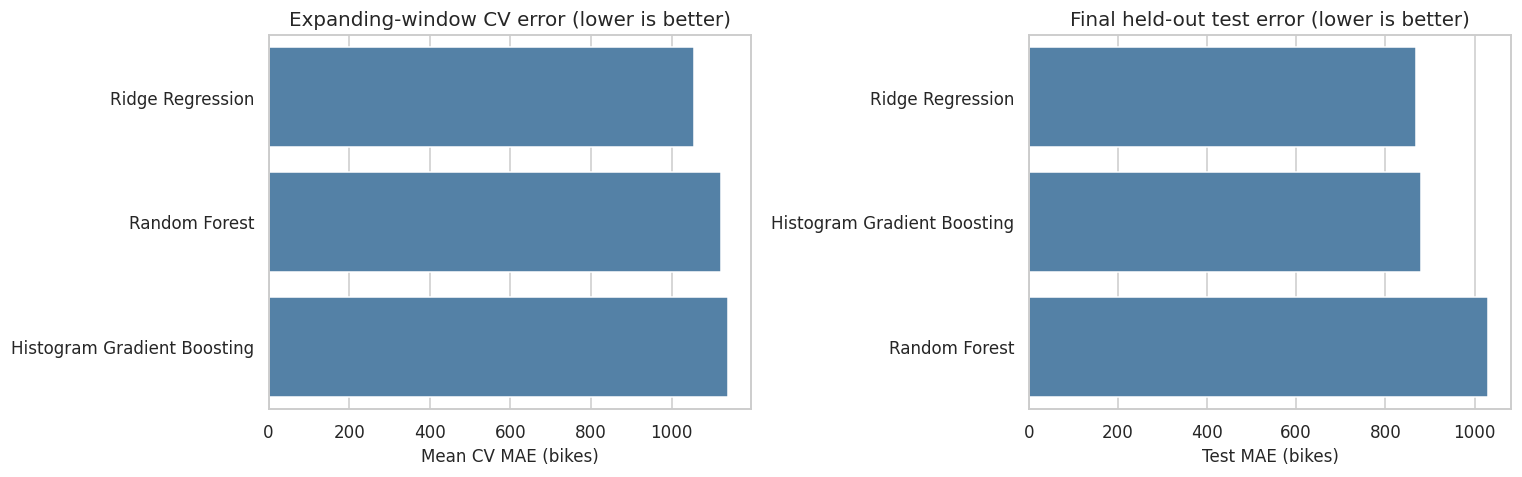

In [19]:
# Plot model comparison.
# Compare validation and test errors visually. The model choice must follow validation results, not whichever happens to win on the test set.
fig,axs=plt.subplots(1,2,figsize=(14,4.5))
sns.barplot(data=cv_table,x='CV MAE (bikes)',y='Model',color='steelblue',ax=axs[0]);axs[0].set(title='Expanding-window CV error (lower is better)',xlabel='Mean CV MAE (bikes)',ylabel='')
sns.barplot(data=test_table,x='MAE (bikes)',y='Model',color='steelblue',ax=axs[1]);axs[1].set(title='Final held-out test error (lower is better)',xlabel='Test MAE (bikes)',ylabel='')
plt.tight_layout()
plt.show()

### 3.5 · Actual vs predicted daily rentals (CV-selected model)

#### Code cell 18 — Plot actual versus predicted demand

**What this code does:** Overlay real rental counts and model predictions to see where the model follows the pattern and where it misses.

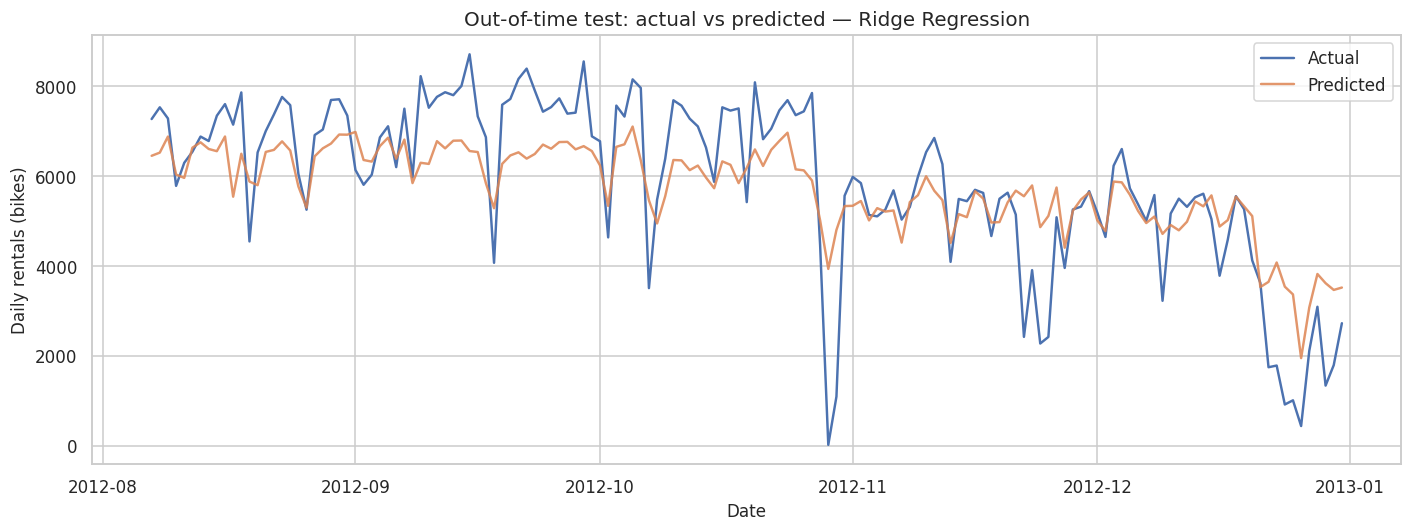

In [20]:
# Plot actual versus predicted demand.
# Overlay real rental counts and model predictions to see where the model follows the pattern and where it misses.
final_model=fitted[selected_name]
final_pred=predictions[selected_name]
fig,ax=plt.subplots(figsize=(13,5))
ax.plot(test_dates.to_numpy(),y_test.to_numpy(),label='Actual',linewidth=1.6)
ax.plot(test_dates.to_numpy(),final_pred,label='Predicted',linewidth=1.6,alpha=.85)
ax.set(title=f'Out-of-time test: actual vs predicted — {selected_name}',xlabel='Date',ylabel='Daily rentals (bikes)');ax.legend()
plt.tight_layout()
plt.show()

### 3.6 · Prediction scatter and residual diagnostics

#### Code cell 19 — Inspect prediction errors

**What this code does:** A scatter plot checks how close predictions are to actual values. Residuals show whether errors have a pattern.

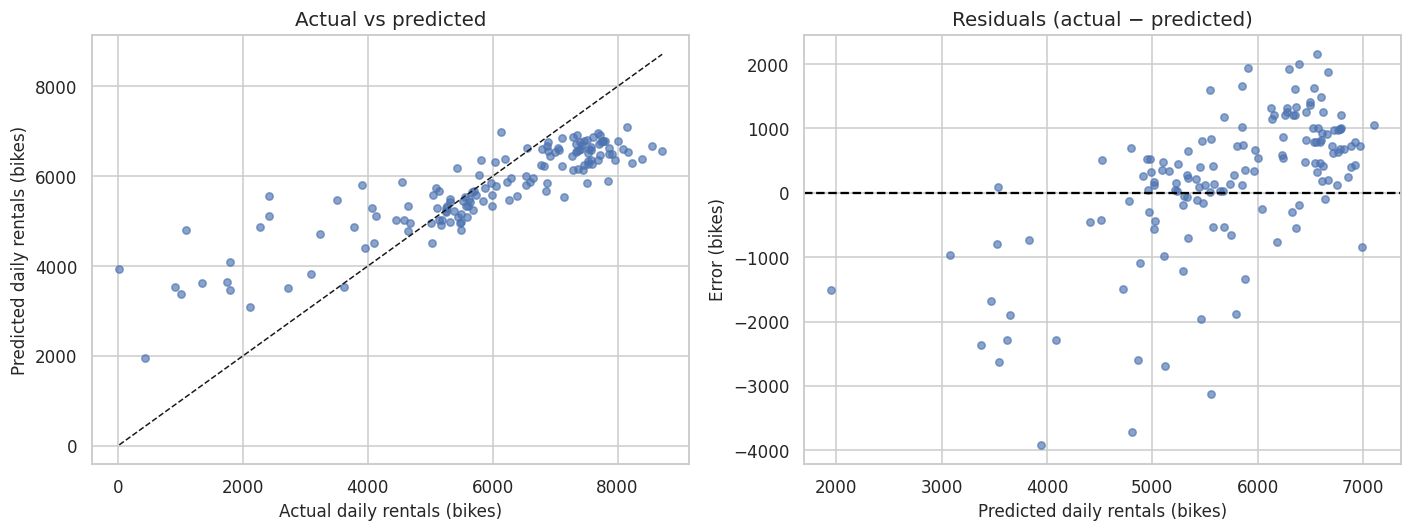

Mean residual (bias): 169.2 bikes


In [21]:
# Inspect prediction errors.
# A scatter plot checks how close predictions are to actual values. Residuals show whether errors have a pattern.
residuals=y_test.to_numpy()-final_pred
fig,axs=plt.subplots(1,2,figsize=(13,5))
axs[0].scatter(y_test,final_pred,alpha=.65,s=23);bounds=[min(y_test.min(),final_pred.min()),max(y_test.max(),final_pred.max())]
axs[0].plot(bounds,bounds,'k--',linewidth=1);axs[0].set(title='Actual vs predicted',xlabel='Actual daily rentals (bikes)',ylabel='Predicted daily rentals (bikes)')
axs[1].scatter(final_pred,residuals,alpha=.65,s=23);axs[1].axhline(0,color='black',linestyle='--');axs[1].set(title='Residuals (actual − predicted)',xlabel='Predicted daily rentals (bikes)',ylabel='Error (bikes)')
plt.tight_layout()
plt.show()
print('Mean residual (bias):',round(float(np.mean(residuals)),2),'bikes')

### 3.7 · Compare to a simple training-mean baseline

#### Code cell 20 — Compare against a simple baseline

**What this code does:** A model should beat a naive prediction based on average training demand. This checks whether ML adds value.

In [22]:
# Compare against a simple baseline.
# A model should beat a naive prediction based on average training demand. This checks whether ML adds value.
baseline=np.full(len(y_test),y_train.mean())
baseline_mae=mean_absolute_error(y_test,baseline)
selected_mae=mean_absolute_error(y_test,final_pred)
print(f'Training-mean baseline test MAE: {baseline_mae:,.1f} bikes')
print(f'CV-selected model test MAE:      {selected_mae:,.1f} bikes')
print(f'Improvement vs baseline:        {100*(baseline_mae-selected_mae)/baseline_mae:.1f}% (positive is better)')

Training-mean baseline test MAE: 2,290.4 bikes
CV-selected model test MAE:      868.3 bikes
Improvement vs baseline:        62.1% (positive is better)


### 3.8 · Permutation feature importance on held-out dates

#### Code cell 21 — Identify influential features

**What this code does:** Permutation importance measures how much model accuracy changes when one feature is shuffled. This is diagnostic, not proof of cause.

,Feature,MAE increase (bikes),SD
8,atemp,228.13,17.25
7,temp,207.46,18.23
0,season,121.43,12.41
5,weathersit,89.37,8.56
10,windspeed,75.21,19.94
1,mnth,53.00,12.04
9,hum,41.67,15.99
2,weekday,14.75,4.73
4,workingday,11.08,2.88
3,holiday,4.16,1.45


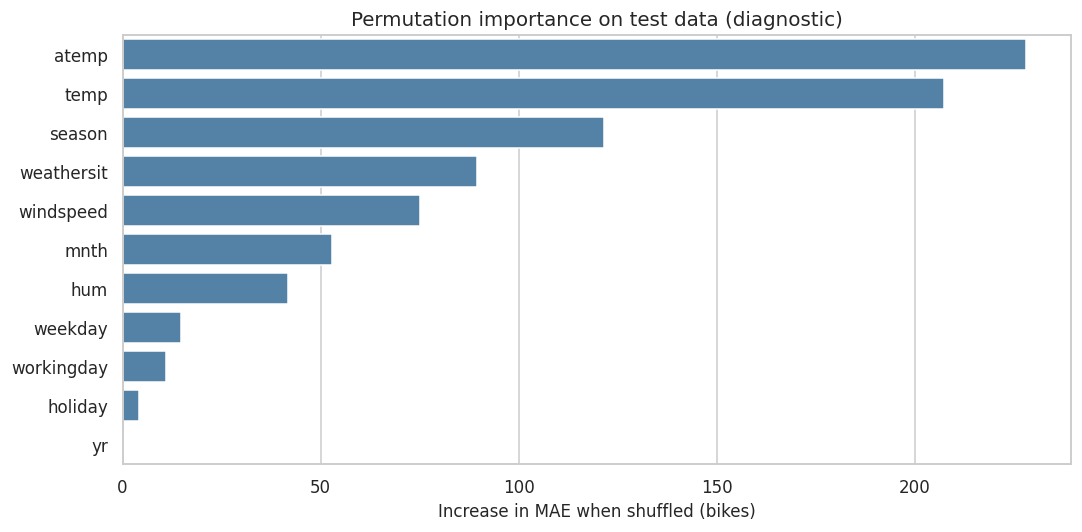

In [23]:
# Identify influential features.
# Permutation importance measures how much model accuracy changes when one feature is shuffled. This is diagnostic, not proof of cause.
# Diagnostic only: do not use this holdout-derived ranking to retune the selected model.
importance=permutation_importance(final_model,X_test,y_test,n_repeats=5,random_state=SEED,scoring='neg_mean_absolute_error',n_jobs=1)
importance_df=pd.DataFrame({'Feature':features,'MAE increase (bikes)':importance.importances_mean,'SD':importance.importances_std}).sort_values('MAE increase (bikes)',ascending=False)
display(importance_df.round(2))
fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(data=importance_df,x='MAE increase (bikes)',y='Feature',color='steelblue',ax=ax)
ax.set(title='Permutation importance on test data (diagnostic)',xlabel='Increase in MAE when shuffled (bikes)',ylabel='')
plt.tight_layout()
plt.show()

### 3.9 · Illustrative prediction for one held-out day

#### Code cell 22 — Show one example prediction

**What this code does:** Take one unseen test row and show its predicted bike count alongside the actual count.

In [24]:
# Show one example prediction.
# Take one unseen test row and show its predicted bike count alongside the actual count.
example_idx=0
example_features=X_test.iloc[[example_idx]]
example_date=test_dates.iloc[example_idx].date()
example_prediction=float(np.clip(final_model.predict(example_features)[0],0,None))
example_actual=float(y_test.iloc[example_idx])
print('Date:',example_date)
print('Predicted rentals:',round(example_prediction),'bikes')
print('Actual rentals:   ',round(example_actual),'bikes')
print('Absolute error:    ',round(abs(example_actual-example_prediction)),'bikes')
print('Inputs are historical observations; for genuine future predictions use forecast weather.')

Date: 2012-08-07
Predicted rentals: 6455 bikes
Actual rentals:    7273 bikes
Absolute error:     818 bikes
Inputs are historical observations; for genuine future predictions use forecast weather.


## 4 · Task 3: Model comparison and production recommendation

#### Code cell 23 — Generate the model comparison report

**What this code does:** Create the required written performance report automatically from measured validation and test scores.

In [25]:
# Generate the model comparison report.
# Create the required written performance report automatically from measured validation and test scores.
selected_cv=cv_table.loc[cv_table.Model.eq(selected_name)].iloc[0]
selected_test=test_table.loc[test_table.Model.eq(selected_name)].iloc[0]
summary=f"""### Production recommendation: **{selected_name}**

- **Selection rule:** lowest mean MAE across 4 expanding-window validation folds on training data.
- **Training CV MAE:** {selected_cv['CV MAE (bikes)']:,.1f} bikes.
- **Final chronological test MAE:** {selected_test['MAE (bikes)']:,.1f} bikes.
- **Final test RMSE:** {selected_test['RMSE (bikes)']:,.1f} bikes.
- **Final test R²:** {selected_test['R²']:.3f}.
- **Test interval:** {test_dates.min().date()} through {test_dates.max().date()} ({len(y_test)} days).

**Why this model:** it minimized cross-validated absolute error without consulting the held-out test set. The test set is used once for final reporting. It is a **historical production candidate**, not a validated modern deployment.

**Deployment caveats:** 2011–2012 data may not reflect current patterns; weather must be forecast at prediction time; re-train on recent data and monitor MAE, drift and bias before real-world use.
"""
display(Markdown(summary))

### Production recommendation: **Ridge Regression**

- **Selection rule:** lowest mean MAE across 4 expanding-window validation folds on training data.
- **Training CV MAE:** 1,056.0 bikes.
- **Final chronological test MAE:** 868.3 bikes.
- **Final test RMSE:** 1,135.8 bikes.
- **Final test R²:** 0.633.
- **Test interval:** 2012-08-07 through 2012-12-31 (147 days).

**Why this model:** it minimized cross-validated absolute error without consulting the held-out test set. The test set is used once for final reporting. It is a **historical production candidate**, not a validated modern deployment.

**Deployment caveats:** 2011–2012 data may not reflect current patterns; weather must be forecast at prediction time; re-train on recent data and monitor MAE, drift and bias before real-world use.


## 5 · Task 4: Challenges encountered and techniques used

#### Code cell 24 — Document project challenges

**What this code does:** Describe problems such as target leakage, categorical values, time order, and overfitting, along with the chosen solutions.

In [26]:
# Document project challenges.
# Describe problems such as target leakage, categorical values, time order, and overfitting, along with the chosen solutions.
challenges=pd.DataFrame([
 ['Target leakage','casual + registered = cnt; including them would reveal the target','Excluded casual and registered from all model features','Validates realistic pre-rental prediction'],
 ['Time dependence','Random splits can allow later dates to inform earlier predictions','Chronological 80/20 split plus expanding-window CV','Simulates forward-looking evaluation'],
 ['Categorical encoding','Season, month, weekday and weather codes represent categories','OneHotEncoder with unknown-category handling in a pipeline','Avoids assuming arbitrary numeric distances'],
 ['Scale differences','Humidity, wind and calendar features have different scales','Train-fold-only imputation and scaling in preprocessing pipeline','Prevents inconsistent scaling and leakage'],
 ['Limited historical coverage','Only 2011–2012 and 731 daily records','Simple baseline, 3 candidate models, held-out testing','Avoids overclaiming modern deployment readiness'],
 ['Source definition conflict','Season labels in capstone brief differ from Readme.txt','Follow original Readme.txt and disclose mapping','Keeps charts interpretable and reproducible'],
 ['Weather forecast uncertainty','Historical observed weather is not available before a future date','Require forecast weather for deployment','Prevents future-information leakage in practice'],
 ['Data consistency','Daily and hourly files must be reconcilable','Check sum of hourly rentals against daily cnt','Detects potential aggregation issues'],
 ['Model overfitting','Flexible models may fit historical noise','Time-series CV, leaf-size / regularization controls, holdout diagnostics','Improves trust in reported performance']
],columns=['Challenge','Issue','Technique used','Reasoning'])
display(challenges)

,Challenge,Issue,Technique used,Reasoning
0,Target leakage,casual + registered = cnt; including them woul...,Excluded casual and registered from all model ...,Validates realistic pre-rental prediction
1,Time dependence,Random splits can allow later dates to inform ...,Chronological 80/20 split plus expanding-windo...,Simulates forward-looking evaluation
2,Categorical encoding,"Season, month, weekday and weather codes repre...",OneHotEncoder with unknown-category handling i...,Avoids assuming arbitrary numeric distances
3,Scale differences,"Humidity, wind and calendar features have diff...",Train-fold-only imputation and scaling in prep...,Prevents inconsistent scaling and leakage
4,Limited historical coverage,Only 2011–2012 and 731 daily records,"Simple baseline, 3 candidate models, held-out ...",Avoids overclaiming modern deployment readiness
5,Source definition conflict,Season labels in capstone brief differ from Re...,Follow original Readme.txt and disclose mapping,Keeps charts interpretable and reproducible
6,Weather forecast uncertainty,Historical observed weather is not available b...,Require forecast weather for deployment,Prevents future-information leakage in practice
7,Data consistency,Daily and hourly files must be reconcilable,Check sum of hourly rentals against daily cnt,Detects potential aggregation issues
8,Model overfitting,Flexible models may fit historical noise,"Time-series CV, leaf-size / regularization con...",Improves trust in reported performance


## 6 · Final findings and conclusions

#### Code cell 25 — Write the final conclusion

**What this code does:** Summarize the dataset, EDA, selected model, test performance, and production limitations using calculated results.

In [27]:
# Write the final conclusion.
# Summarize the dataset, EDA, selected model, test performance, and production limitations using calculated results.
best_season=season_stats.index[0]
conclusion=f"""### Final conclusion

The dataset contains **{len(day):,} daily observations** and **{len(hour):,} hourly observations** from 2011–2012. The target is total daily rentals (`cnt`). The highest observed seasonal mean is **{best_season}**. The data was checked for missing values, duplicate rows, and target identity; hourly-to-daily reconciliation was also performed.

Three models were compared using expanding-window cross-validation: Ridge Regression, Random Forest, and Histogram Gradient Boosting. **{selected_name}** was selected on training-only CV. Its held-out test MAE is **{selected_mae:,.1f} bikes**, RMSE is **{selected_test['RMSE (bikes)']:,.1f} bikes**, and R² is **{selected_test['R²']:.3f}**.

**Limitations:** Historical patterns and observed weather may not transfer to real-time forecasts or modern demand. This notebook provides a reproducible academic proof of concept, not a deployed production system.
"""
display(Markdown(conclusion))

### Final conclusion

The dataset contains **731 daily observations** and **17,379 hourly observations** from 2011–2012. The target is total daily rentals (`cnt`). The highest observed seasonal mean is **Fall**. The data was checked for missing values, duplicate rows, and target identity; hourly-to-daily reconciliation was also performed.

Three models were compared using expanding-window cross-validation: Ridge Regression, Random Forest, and Histogram Gradient Boosting. **Ridge Regression** was selected on training-only CV. Its held-out test MAE is **868.3 bikes**, RMSE is **1,135.8 bikes**, and R² is **0.633**.

**Limitations:** Historical patterns and observed weather may not transfer to real-time forecasts or modern demand. This notebook provides a reproducible academic proof of concept, not a deployed production system.


### 6.1 · Final integrity checks

#### Code cell 26 — Run final correctness checks

**What this code does:** Assertions verify that the target was excluded from features, all rows were accounted for, and predictions are valid.

In [28]:
# Run final correctness checks.
# Assertions verify that the target was excluded from features, all rows were accounted for, and predictions are valid.
assert len(X_train)+len(X_test)==len(day)
assert set(['casual','registered','cnt','instant']).isdisjoint(X_train.columns)
assert np.isfinite(final_pred).all() and (final_pred>=0).all()
assert len(test_table)==3 and len(cv_table)==3
print('ALL CHECKS PASSED: temporal split, leakage exclusions, finite predictions, and model comparisons.')

ALL CHECKS PASSED: temporal split, leakage exclusions, finite predictions, and model comparisons.


### 6.2 · Optional: Export summary tables and fitted model
Run the cell below to save CSV summaries and a fitted `joblib` model. **The single notebook remains the required final submission.** In Colab, generated files appear in the Files panel. The fitted model is a historical demonstration and should not be deployed without fresh validation.

#### Code cell 27 — Export reports and model

**What this code does:** Save the model comparison tables, feature importance, and fitted model as files that can be downloaded from Colab.

In [29]:
# Export reports and model.
# Save the model comparison tables, feature importance, and fitted model as files that can be downloaded from Colab.
import joblib
cv_table.to_csv('bike_cv_model_comparison.csv',index=False)
test_table.to_csv('bike_test_model_comparison.csv',index=False)
importance_df.to_csv('bike_feature_importance.csv',index=False)
joblib.dump(final_model,'bike_rental_selected_model.joblib')
print('Saved 3 CSV reports and the fitted model in the current working directory.')

Saved 3 CSV reports and the fitted model in the current working directory.


## References and submission notes
1. Hadi Fanaee-T and João Gama (2013), *Event labeling combining ensemble detectors and background knowledge*, Progress in Artificial Intelligence. DOI: `10.1007/s13748-013-0040-3`.
2. Capital Bikeshare historical system data (Washington, D.C.), described in the supplied `Readme.txt`.
3. Project brief: `PRCP-1018-BikeRental.docx`.

